# Regression in scikit-learn

In [33]:
#import libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# others
from sklearn.model_selection  import train_test_split
from sklearn.linear_model import LinearRegression

In [34]:
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [35]:
df_linear = df[["age", "fare"]]
df_linear

,age,fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
886,27.0,13.0000
887,19.0,30.0000
888,NaN,23.4500
889,26.0,30.0000


In [36]:
#simple linear regression
X = df[["age"]]
y =  df["fare"]

In [37]:
y.isnull().sum() / len(y) *100

np.float64(0.0)

In [38]:
X

,age
0,22.0
1,38.0
2,26.0
3,35.0
4,35.0
...,...
886,27.0
887,19.0
888,NaN
889,26.0


In [39]:
df_linear.age.fillna(value = df_linear["age"].mean(), inplace=True)

C:\Users\server22\AppData\Local\Temp\ipykernel_11676\1333599115.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_linear.age.fillna(value = df_linear["age"].mean(), inplace=True)
C:\Users\server22\AppData\Local\Temp\ipykernel_11676\1333599115.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_linear.age.fillna(value = df_linear["age"]

In [40]:
X

,age
0,22.0
1,38.0
2,26.0
3,35.0
4,35.0
...,...
886,27.0
887,19.0
888,NaN
889,26.0


In [41]:
df_linear.isnull().sum()

age     0
fare    0
dtype: int64

In [42]:
y.isnull().sum()

np.int64(0)

In [43]:
df_linear.shape

(891, 2)

In [44]:
y.shape

(891,)

In [45]:
df_linear.isnull().sum() /len(X) *100

age     0.0
fare    0.0
dtype: float64

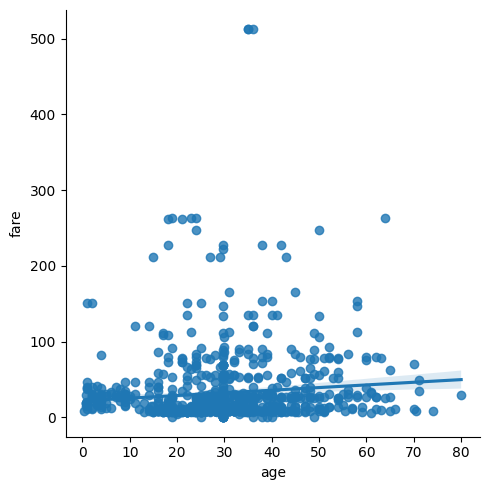

In [46]:
#plot 
sns.lmplot(data=df_linear, x = "age" , y="fare")

<Axes: ylabel='age'>

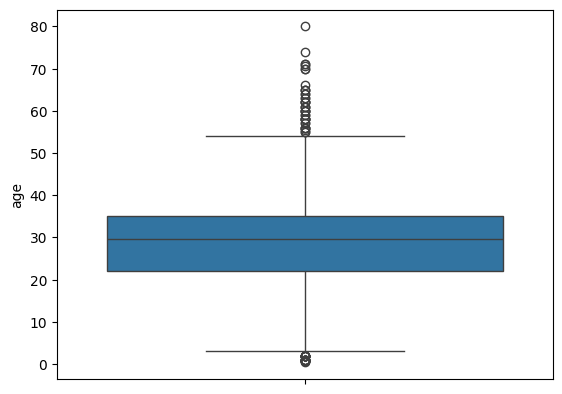

In [47]:
sns.boxplot(data=df_linear,  y="age" )

In [48]:
df_linear = df_linear[(df_linear["age"]> 5)& (df_linear["age"]< 55)]

<Axes: ylabel='fare'>

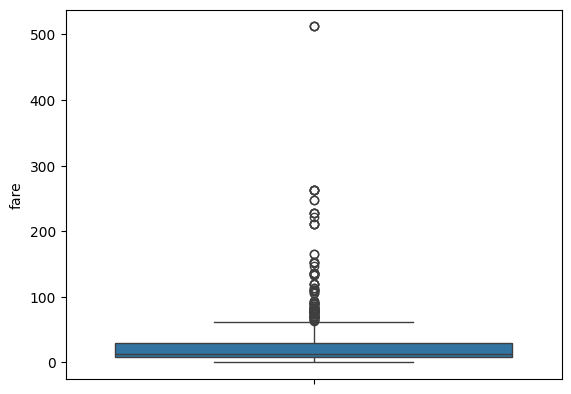

In [49]:
sns.boxplot(data=df_linear, y="fare")

In [50]:
df_linear["fare"].min()

np.float64(0.0)

In [51]:
df_linear = df_linear[(df_linear["fare"]> 5) & (df_linear["fare"]<35) ]

In [52]:
X = df_linear[["age"]]
y = df_linear["fare"]

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# model ko bulyate hn 
model = LinearRegression()

# model ko train kry gy
model.fit(X,y) 

# predict
model.predict([[25]])



c:\Users\server22\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([13.45411678])

In [54]:
# model evaluation with matrics
## r2
## mean squre error  MSE
## mean absolute error  MAE
## root mean square error  RMSE
X_train, X_test, y_train , y_test = train_test_split(X,y, train_size=0.8)

# model ko bula rehe hn
model  = LinearRegression()

# train
model.fit(X_train, y_train)

#prediction
predictions = model.predict(X_test)



<Axes: xlabel='fare'>

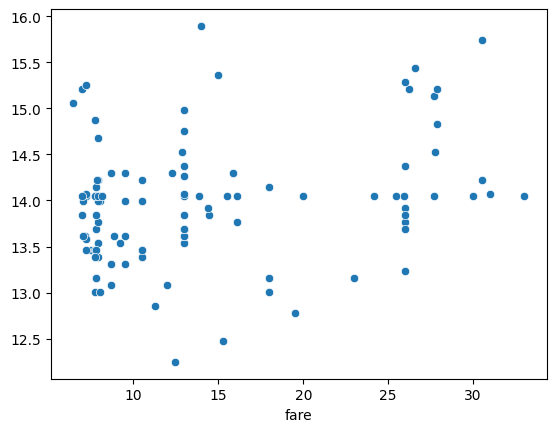

In [55]:
#compare 
sns.scatterplot(x=y_test, y= predictions)

In [56]:
model.score(X_test,y_test) # accuracy ko check krny ky lie use krty hn is code ko 

0.025501104438988897

In [59]:
print(len(y_test), len(predictions))


123 123


In [61]:
import numpy as np
print(np.isnan(y_test).sum(), np.isnan(predictions).sum())


0 0


In [62]:
print(y_test.dtype)
print(predictions.dtype)


float64
float64


In [63]:
ValueError: ...


In [66]:
MSE = mean_squared_error(y_true=y_test, y_pred=predictions)
RMSE = MSE ** 0.5


In [65]:
!pip install -U scikit-learn



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [68]:
from sklearn.metrics import mean_squared_error , mean_absolute_error,r2_score 

MAE = mean_absolute_error (y_true=y_test, y_pred=predictions)
MSE =  mean_squared_error (y_true=y_test, y_pred=predictions)
#RMSE = mean_squared_error (y_true=y_test, y_pred=predictions, squared=False)
R2 =r2_score (y_true=y_test, y_pred=predictions)

print("MAE: ",MAE)
print("MSE: ",MSE)
print("RMSE: ", RMSE)
print("R_squared: ", R2)

MAE:  6.1597865660261775
MSE:  53.666831927498265
RMSE:  7.325764938045601
R_squared:  0.025501104438988897


In [69]:
import numpy as np
RMSE = np.sqrt(MSE)
RMSE

np.float64(7.325764938045601)